# **INF01017 - Aprendizado de Máquina - INF/UFRGS**
#### *Profa. Mariana Recamonde Mendoza*

## Trabalho Prático Final - Parte 2 (T2): Otimização e interpretação de modelos

### Detector de Ataques Cardíacos - notebook de validação

**Integrantes:** Gabriel Pieruccini Knopp, Vítor Santana Feijó

Este notebook continua o T1 (`Notebook - Detector de Ataques Cardíacos.ipynb`), que selecionou para o T2 os modelos **Regressão Logística**, **KNN** e **Random Forest**. Os dados, o pré-processamento e a divisão treino/teste são exatamente os mesmos do T1.

---

**Roteiro**

1. Configuração do ambiente
2. Dados e pré-processamento (mesmo protocolo do T1)
3. Protocolo de otimização
4. Funções do protocolo
5. Nested cross-validation
6. Estabilidade dos hiperparâmetros
7. Modelo final de cada algoritmo
8. Avaliação no conjunto de teste
9. Nested CV × teste
10. Melhor modelo (decisão do grupo)
11. Análise de erros (agregada)
12. Avaliação desagregada por fatores
13. Interpretabilidade da Regressão Logística

# 1. Configuração do ambiente

Bibliotecas: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` e `optuna` (as mesmas usadas nos notebooks da disciplina). O Optuna não vem instalado no Google Colab, então a célula abaixo o instala quando necessário.

In [1]:
## Carregando as bibliotecas necessárias
%matplotlib inline
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
try:
    import optuna
except ImportError:  # o Google Colab não traz o Optuna instalado
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])
    import optuna

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

optuna.logging.set_verbosity(optuna.logging.WARNING)

## Semente única para todos os processos aleatórios (reprodutibilidade dos experimentos)
RANDOM_STATE = 42

## Configuração visual dos gráficos (mesma do T1)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "grid.color": "#e1e0d9",
})
CORES_MODELO = {"Regressão Logística": "#2a78d6", "KNN": "#eb6834", "Random Forest": "#1baf7a"}
NOMES_DOENCA = {0: "sem doença", 1: "com doença"}

# 2. Dados e pré-processamento (mesmo protocolo do T1)

Reproduzimos exatamente as etapas da Seção 5 do T1:

1. recodificação do alvo (`doenca` = 1 - `target`, com **1 = com doença** como classe positiva);
2. remoção da instância duplicada;
3. divisão treino/teste estratificada 80/20 com `random_state = 42`. Como o código e a semente são os mesmos, o **conjunto de teste é o mesmo reservado no T1** e só é usado na Seção 8;
4. marcação dos códigos de ausência (`ca = 4` e `thal = 0`) como `NaN`;
5. `ColumnTransformer` com imputação pela mediana, padronização dos numéricos e one-hot dos nominais, reajustado apenas nos dados de treino de cada fold.

In [2]:
## Carregando os dados (local ou a partir do GitHub, no Colab)
URL_DADOS = "https://raw.githubusercontent.com/vitorsfeijo/Trabalho_ML/main/heart.csv"
try:
    df_original = pd.read_csv("heart.csv", encoding="utf-8-sig")
except FileNotFoundError:
    df_original = pd.read_csv(URL_DADOS, encoding="utf-8-sig")

## 1) Recodificação do alvo e 2) remoção da duplicata
df = df_original.copy()
df["doenca"] = 1 - df["target"]
df = df.drop(columns="target").drop_duplicates(keep="first").reset_index(drop=True)

## 3) Divisão treino/teste (idêntica à do T1)
X = df.drop(columns="doenca")
y = df["doenca"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

## 4) Marcação dos códigos de ausência como valores faltantes
DOMINIO_VALIDO = {"ca": {0, 1, 2, 3}, "thal": {1, 2, 3}}


def marcar_ausentes(dados):
    dados = dados.copy()
    for col, dominio in DOMINIO_VALIDO.items():
        dados[col] = dados[col].where(dados[col].isin(dominio))
    return dados


X_train, X_test = marcar_ausentes(X_train), marcar_ausentes(X_test)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print(pd.DataFrame({"treino": y_train.value_counts(normalize=True),
                    "teste": y_test.value_counts(normalize=True)}).rename(index=NOMES_DOENCA).round(3))

Treino: (241, 13) | Teste: (61, 13)
            treino  teste
doenca                   
sem doença   0.544  0.541
com doença   0.456  0.459


In [3]:
## 5) Pré-processamento (idêntico ao T1)
ATR_PADRONIZADOS = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
ATR_BINARIOS = ["sex", "fbs", "exang"]
ATR_NOMINAIS = ["cp", "restecg", "slope", "thal"]

preprocessador = ColumnTransformer([
    ("numericos", Pipeline([("imputacao", SimpleImputer(strategy="median")),
                            ("padronizacao", StandardScaler())]), ATR_PADRONIZADOS),
    ("binarios", "passthrough", ATR_BINARIOS),
    ("nominais", Pipeline([("imputacao", SimpleImputer(strategy="median")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), ATR_NOMINAIS),
])

# 3. Protocolo de otimização

Decisões do grupo para o T2:

| Etapa | Decisão |
|---|---|
| Divisão dos dados | Holdout + nested cross-validation estratificada. O teste (61 pacientes, reservado no T1) só é usado na avaliação final. |
| Nested CV | **5 folds externos** (estimativa de desempenho) × **3 folds internos** (seleção de hiperparâmetros), todos estratificados. As divisões externas são as mesmas para os três modelos. |
| Busca de hiperparâmetros | **Grid Search** para a Regressão Logística e o KNN; **Optuna** (TPE, 50 trials) para o Random Forest. |
| Limiar de decisão | Otimizado na CV interna, como mais um hiperparâmetro (ver abaixo). |
| Métrica principal | F1 da classe positiva (com doença), como no T1. Também são reportadas acurácia, precisão, recall, ROC-AUC e PR-AUC. |
| Modelo final | A mesma busca é repetida em todo o conjunto de treino (CV estratificada de 3 folds); o modelo com a configuração e o limiar escolhidos é treinado em todo o treino e avaliado **uma única vez** no teste. |

**Limiar como hiperparâmetro.** Para cada configuração candidata, o modelo é treinado em cada fold interno de treino e gera probabilidades para o fold interno de validação. Para cada limiar da grade (0,10 a 0,90, de 0,05 em 0,05), calcula-se o F1 em cada fold interno e a média entre os folds. A busca escolhe o par (configuração, limiar) com maior F1 médio; em caso de empate entre limiares, fica o mais próximo de 0,5. Nenhuma etapa usa os folds externos ou o teste.

In [4]:
## Modelos base (os hiperparâmetros buscados são definidos abaixo)
## Regressão Logística: penalty="elasticnet" com l1_ratio = 0 (L2) ou 1 (L1) funciona igual em versões novas e
## antigas do scikit-learn (inclusive a do Colab); o solver "saga" é o que aceita as duas penalidades.
MODELOS_BASE = {
    "Regressão Logística": LogisticRegression(penalty="elasticnet", solver="saga", max_iter=5000,
                                              random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

## Espaços de busca do Grid Search (Regressão Logística e KNN)
ESPACOS_GRID = {
    "Regressão Logística": {
        "C": [0.001, 0.01, 0.1, 1, 10, 100],   # 0,001 a 100 em escala log
        "l1_ratio": [0.0, 1.0],                 # 0 = L2, 1 = L1
    },
    "KNN": {
        "n_neighbors": list(range(1, 41)),       # 1 a 40
        "weights": ["uniform", "distance"],
        "p": [1, 2],                             # 1 = Manhattan, 2 = Euclidiana
    },
}

## Espaço de busca do Optuna (Random Forest)
N_TRIALS_RF = 50
MAX_FEATURES = {"sqrt": "sqrt", "log2": "log2", "0.5": 0.5}


def sugerir_rf(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth": trial.suggest_categorical("max_depth", [None] + list(range(2, 16))),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": MAX_FEATURES[trial.suggest_categorical("max_features", list(MAX_FEATURES))],
    }


## Grade de limiares de decisão avaliada na CV interna
LIMIARES = np.round(np.arange(0.10, 0.91, 0.05), 2)

for nome, espaco in ESPACOS_GRID.items():
    print(f"{nome}: {len(ParameterGrid(espaco))} configurações × {len(LIMIARES)} limiares")
print(f"Random Forest: {N_TRIALS_RF} trials do Optuna × {len(LIMIARES)} limiares")

Regressão Logística: 12 configurações × 17 limiares
KNN: 160 configurações × 17 limiares
Random Forest: 50 trials do Optuna × 17 limiares


# 4. Funções do protocolo

In [5]:
def construir_pipeline(nome, params):
    """Pipeline completo (pré-processamento + classificador) com os hiperparâmetros informados."""
    return Pipeline([("preprocessamento", clone(preprocessador)),
                     ("classificador", clone(MODELOS_BASE[nome]).set_params(**params))])


def avaliar_configuracao(nome, params, X, y, cv):
    """F1 médio nos folds da CV para cada limiar; devolve o melhor F1 médio e o limiar correspondente."""
    f1_por_limiar = np.zeros((cv.get_n_splits(), len(LIMIARES)))
    for i, (idx_treino, idx_valid) in enumerate(cv.split(X, y)):
        pipe = construir_pipeline(nome, params).fit(X.iloc[idx_treino], y.iloc[idx_treino])
        prob = pipe.predict_proba(X.iloc[idx_valid])[:, 1]
        f1_por_limiar[i] = [f1_score(y.iloc[idx_valid], (prob >= t).astype(int), zero_division=0)
                            for t in LIMIARES]
    medias = f1_por_limiar.mean(axis=0)
    empatados = np.flatnonzero(np.isclose(medias, medias.max()))
    j = empatados[np.argmin(np.abs(LIMIARES[empatados] - 0.5))]   # empate: limiar mais próximo de 0,5
    return medias[j], float(LIMIARES[j])


def buscar_hiperparametros(nome, X, y, cv, semente):
    """Grid Search (Regressão Logística, KNN) ou Optuna (Random Forest), com o limiar como hiperparâmetro."""
    if nome in ESPACOS_GRID:
        melhor = None
        for params in ParameterGrid(ESPACOS_GRID[nome]):
            f1_medio, limiar = avaliar_configuracao(nome, params, X, y, cv)
            if melhor is None or f1_medio > melhor["f1_interno"]:
                melhor = {"params": params, "limiar": limiar, "f1_interno": f1_medio}
        return melhor

    def objetivo(trial):
        params = sugerir_rf(trial)
        f1_medio, limiar = avaliar_configuracao(nome, params, X, y, cv)
        trial.set_user_attr("params", params)
        trial.set_user_attr("limiar", limiar)
        return f1_medio

    estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=semente))
    estudo.optimize(objetivo, n_trials=N_TRIALS_RF)
    return {"params": estudo.best_trial.user_attrs["params"], "limiar": estudo.best_trial.user_attrs["limiar"],
            "f1_interno": estudo.best_value}


def calcular_metricas(y_true, prob, limiar):
    """Métricas com o limiar de decisão informado (ROC-AUC e PR-AUC não dependem do limiar)."""
    pred = (prob >= limiar).astype(int)
    return {"F1": f1_score(y_true, pred), "Acurácia": accuracy_score(y_true, pred),
            "Precisão": precision_score(y_true, pred, zero_division=0), "Recall": recall_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob), "PR-AUC": average_precision_score(y_true, prob)}


METRICAS = ["F1", "Acurácia", "Precisão", "Recall", "ROC-AUC", "PR-AUC"]

# 5. Nested cross-validation

Para cada modelo e cada fold externo: a busca (com o limiar) é feita **somente** nos 4 folds externos de treino, usando a CV interna de 3 folds; o pipeline com a configuração escolhida é retreinado nesses 4 folds e avaliado no fold externo restante, com o limiar escolhido. As probabilidades e predições de cada paciente no seu fold externo são guardadas para análises posteriores.

In [6]:
cv_externo = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

resultados_nested = {}
predicoes_nested = {}
for nome in MODELOS_BASE:
    inicio = time.perf_counter()
    linhas = []
    prob_oof = pd.Series(np.nan, index=X_train.index)
    pred_oof = pd.Series(-1, index=X_train.index)
    for dobra, (idx_treino, idx_teste) in enumerate(cv_externo.split(X_train, y_train), start=1):
        cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE + dobra)
        X_ext_treino, y_ext_treino = X_train.iloc[idx_treino], y_train.iloc[idx_treino]
        X_ext_teste, y_ext_teste = X_train.iloc[idx_teste], y_train.iloc[idx_teste]

        melhor = buscar_hiperparametros(nome, X_ext_treino, y_ext_treino, cv_interno, semente=RANDOM_STATE + dobra)
        pipe = construir_pipeline(nome, melhor["params"]).fit(X_ext_treino, y_ext_treino)
        prob = pipe.predict_proba(X_ext_teste)[:, 1]

        prob_oof.iloc[idx_teste] = prob
        pred_oof.iloc[idx_teste] = (prob >= melhor["limiar"]).astype(int)
        metricas = calcular_metricas(y_ext_teste, prob, melhor["limiar"])
        linhas.append({"Fold externo": dobra, **metricas, "Limiar": melhor["limiar"],
                       "F1 interno": melhor["f1_interno"], **melhor["params"]})
        print(f"{nome:20s} fold {dobra}: F1 externo = {metricas['F1']:.3f} | limiar = {melhor['limiar']:.2f} "
              f"| {melhor['params']}")

    resultados_nested[nome] = pd.DataFrame(linhas).set_index("Fold externo")
    predicoes_nested[nome] = pd.DataFrame({"prob": prob_oof, "pred": pred_oof})
    print(f"{nome:20s} tempo: {time.perf_counter() - inicio:.0f} s\n")

Regressão Logística  fold 1: F1 externo = 0.889 | limiar = 0.50 | {'C': 0.1, 'l1_ratio': 0.0}


Regressão Logística  fold 2: F1 externo = 0.878 | limiar = 0.45 | {'C': 0.1, 'l1_ratio': 0.0}


Regressão Logística  fold 3: F1 externo = 0.762 | limiar = 0.45 | {'C': 1, 'l1_ratio': 1.0}


Regressão Logística  fold 4: F1 externo = 0.833 | limiar = 0.40 | {'C': 0.1, 'l1_ratio': 0.0}


Regressão Logística  fold 5: F1 externo = 0.773 | limiar = 0.40 | {'C': 0.1, 'l1_ratio': 0.0}
Regressão Logística  tempo: 14 s



KNN                  fold 1: F1 externo = 0.792 | limiar = 0.35 | {'n_neighbors': 6, 'p': 1, 'weights': 'distance'}


... (5 outputs left out)

Random Forest        fold 2: F1 externo = 0.821 | limiar = 0.50 | {'n_estimators': 400, 'max_depth': 12, 'min_samples_leaf': 2, 'max_features': 'log2'}


Random Forest        fold 3: F1 externo = 0.829 | limiar = 0.45 | {'n_estimators': 200, 'max_depth': 10, 'min_samples_leaf': 9, 'max_features': 'log2'}


Random Forest        fold 4: F1 externo = 0.851 | limiar = 0.50 | {'n_estimators': 150, 'max_depth': 2, 'min_samples_leaf': 10, 'max_features': 'log2'}


Random Forest        fold 5: F1 externo = 0.783 | limiar = 0.40 | {'n_estimators': 450, 'max_depth': 14, 'min_samples_leaf': 6, 'max_features': 'sqrt'}
Random Forest        tempo: 395 s



,F1,Acurácia,Precisão,Recall,ROC-AUC,PR-AUC
Regressão Logística,0.827 ± 0.058,0.842 ± 0.053,0.832 ± 0.076,0.827 ± 0.081,0.902 ± 0.048,0.901 ± 0.051
KNN,0.811 ± 0.040,0.822 ± 0.047,0.803 ± 0.099,0.836 ± 0.094,0.903 ± 0.037,0.910 ± 0.026
Random Forest,0.808 ± 0.039,0.818 ± 0.054,0.806 ± 0.117,0.827 ± 0.081,0.916 ± 0.032,0.920 ± 0.028


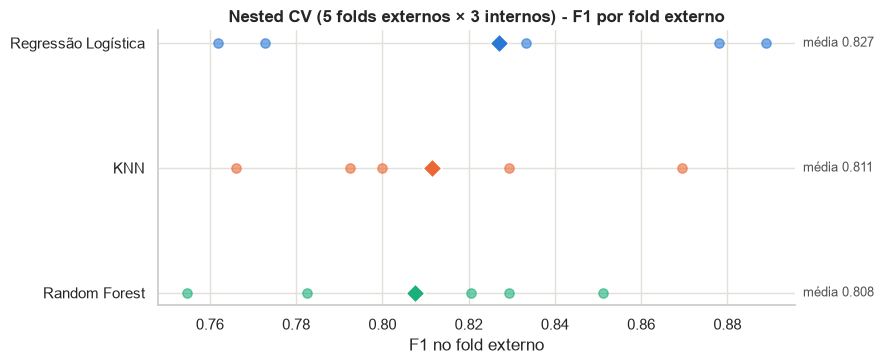

In [7]:
## Resumo: média ± desvio padrão das métricas nos 5 folds externos
media_nested = pd.DataFrame({nome: r[METRICAS].mean() for nome, r in resultados_nested.items()}).T
desvio_nested = pd.DataFrame({nome: r[METRICAS].std() for nome, r in resultados_nested.items()}).T
ordem = media_nested["F1"].sort_values(ascending=False).index
tabela_nested = (media_nested.map("{:.3f}".format) + " ± " + desvio_nested.map("{:.3f}".format)).loc[ordem]
display(tabela_nested)

## F1 de cada fold externo (pontos) e média (losango)
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, nome in enumerate(ordem):
    valores = resultados_nested[nome]["F1"]
    ax.scatter(valores, [i] * len(valores), color=CORES_MODELO[nome], s=45, alpha=0.6, zorder=3)
    ax.scatter(valores.mean(), i, marker="D", s=90, color=CORES_MODELO[nome], edgecolor="white", zorder=4)
    ax.annotate(f"média {valores.mean():.3f}", (1.0, i), xytext=(6, 0), textcoords="offset points",
                xycoords=("axes fraction", "data"), va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(ordem)), ordem)
ax.invert_yaxis()
ax.set_xlabel("F1 no fold externo")
ax.set_title("Nested CV (5 folds externos × 3 internos) - F1 por fold externo")
plt.tight_layout()
plt.show()

# 6. Estabilidade dos hiperparâmetros

Hiperparâmetros e limiar escolhidos pela busca interna em cada fold externo. Valores que mudam de um fold para outro indicam que a configuração ótima depende da partição dos dados.

In [8]:
for nome, resultado in resultados_nested.items():
    colunas = ["Limiar", "F1 interno", "F1"] + [c for c in resultado.columns if c not in METRICAS + ["Limiar", "F1 interno"]]
    print(f"\n{nome}")
    display(resultado[colunas].rename(columns={"F1": "F1 externo"}).round(3))
    variaveis = [c for c in colunas if c not in ("F1 interno", "F1") and resultado[c].astype(str).nunique() > 1]
    print("Variaram entre os folds:", variaveis if variaveis else "nenhum")


Regressão Logística


,Limiar,F1 interno,F1 externo,C,l1_ratio
Fold externo,,,,,
1,0.50,0.837,0.889,0.1,0.0
2,0.45,0.831,0.878,0.1,0.0
3,0.45,0.859,0.762,1.0,1.0
4,0.40,0.822,0.833,0.1,0.0
5,0.40,0.854,0.773,0.1,0.0


Variaram entre os folds: ['Limiar', 'C', 'l1_ratio']

KNN


,Limiar,F1 interno,F1 externo,n_neighbors,p,weights
Fold externo,,,,,,
1,0.35,0.843,0.792,6,1,distance
2,0.50,0.839,0.829,38,1,uniform
3,0.45,0.852,0.800,18,1,distance
4,0.45,0.846,0.870,29,1,distance
5,0.30,0.856,0.766,10,1,distance


Variaram entre os folds: ['Limiar', 'n_neighbors', 'weights']

Random Forest


,Limiar,F1 interno,F1 externo,n_estimators,max_depth,min_samples_leaf,max_features
Fold externo,,,,,,,
1,0.40,0.836,0.755,300,7,7,sqrt
2,0.50,0.825,0.821,400,12,2,log2
3,0.45,0.844,0.829,200,10,9,log2
4,0.50,0.837,0.851,150,2,10,log2
5,0.40,0.854,0.783,450,14,6,sqrt


Variaram entre os folds: ['Limiar', 'n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']


# 7. Modelo final de cada algoritmo

Encerrada a estimativa de desempenho, a mesma busca é repetida em **todo o conjunto de treino** (CV estratificada de 3 folds) para escolher a configuração e o limiar finais. O pipeline é então treinado com todos os 241 pacientes de treino.

In [9]:
cv_final = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

modelos_finais = {}
for nome in MODELOS_BASE:
    inicio = time.perf_counter()
    melhor = buscar_hiperparametros(nome, X_train, y_train, cv_final, semente=RANDOM_STATE)
    pipe = construir_pipeline(nome, melhor["params"]).fit(X_train, y_train)
    modelos_finais[nome] = {"pipeline": pipe, **melhor}
    print(f"{nome:20s} ({time.perf_counter() - inicio:.0f} s) | limiar = {melhor['limiar']:.2f} | "
          f"F1 CV = {melhor['f1_interno']:.3f} | {melhor['params']}")

tabela_config_final = pd.DataFrame({nome: {"Configuração": m["params"], "Limiar": m["limiar"],
                                           "F1 médio na CV (treino)": round(m["f1_interno"], 3)}
                                    for nome, m in modelos_finais.items()}).T
with pd.option_context("display.max_colwidth", None):
    display(tabela_config_final)

Regressão Logística  (3 s) | limiar = 0.45 | F1 CV = 0.822 | {'C': 0.1, 'l1_ratio': 0.0}


KNN                  (31 s) | limiar = 0.45 | F1 CV = 0.856 | {'n_neighbors': 9, 'p': 1, 'weights': 'distance'}


Random Forest        (57 s) | limiar = 0.50 | F1 CV = 0.837 | {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'log2'}


,Configuração,Limiar,F1 médio na CV (treino)
Regressão Logística,"{'C': 0.1, 'l1_ratio': 0.0}",0.45,0.822
KNN,"{'n_neighbors': 9, 'p': 1, 'weights': 'distance'}",0.45,0.856
Random Forest,"{'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'log2'}",0.5,0.837


# 8. Avaliação no conjunto de teste

**Somente agora o conjunto de teste entra no experimento**, uma única vez, com o modelo final e o limiar escolhido de cada algoritmo. Para referência, também é mostrado o F1 que cada modelo teria com o limiar padrão de 0,5.

,F1,Acurácia,Precisão,Recall,ROC-AUC,PR-AUC,Limiar,"F1 com limiar 0,5"
Regressão Logística,0.821,0.836,0.821,0.821,0.922,0.909,0.45,0.830
KNN,0.800,0.820,0.815,0.786,0.893,0.852,0.45,0.815
Random Forest,0.755,0.787,0.800,0.714,0.883,0.868,0.50,0.755


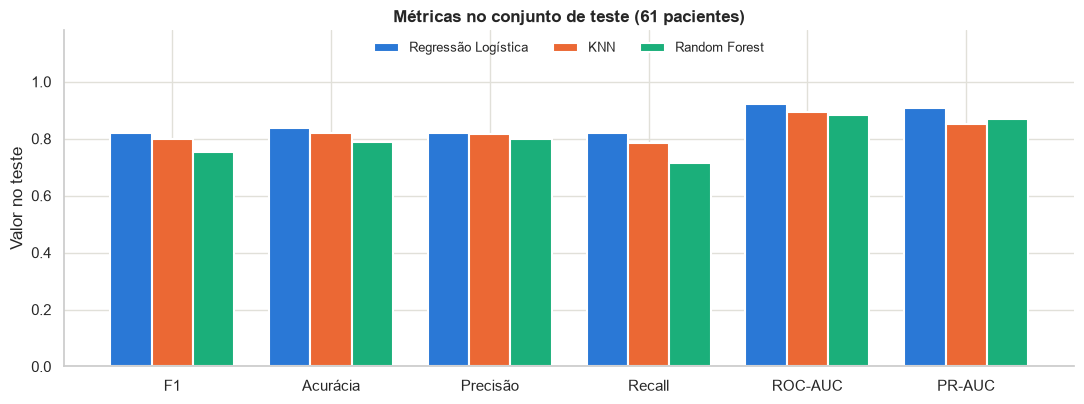

In [10]:
prob_teste = {nome: m["pipeline"].predict_proba(X_test)[:, 1] for nome, m in modelos_finais.items()}

tabela_teste = pd.DataFrame({nome: {**calcular_metricas(y_test, prob_teste[nome], m["limiar"]),
                                    "Limiar": m["limiar"],
                                    "F1 com limiar 0,5": f1_score(y_test, (prob_teste[nome] >= 0.5).astype(int))}
                             for nome, m in modelos_finais.items()}).T
tabela_teste = tabela_teste.sort_values("F1", ascending=False)
display(tabela_teste.round(3))

## Comparação das métricas no teste
fig, ax = plt.subplots(figsize=(11, 4.2))
largura = 0.26
x = np.arange(len(METRICAS))
for i, nome in enumerate(tabela_teste.index):
    barras = ax.bar(x + (i - 1) * largura, tabela_teste.loc[nome, METRICAS], largura, label=nome,
                    color=CORES_MODELO[nome], edgecolor="white", linewidth=1.5)
ax.set_xticks(x, METRICAS)
ax.set_ylim(0, 1.18)
ax.set_ylabel("Valor no teste")
ax.set_title("Métricas no conjunto de teste (61 pacientes)")
ax.legend(loc="upper center", ncol=3, fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

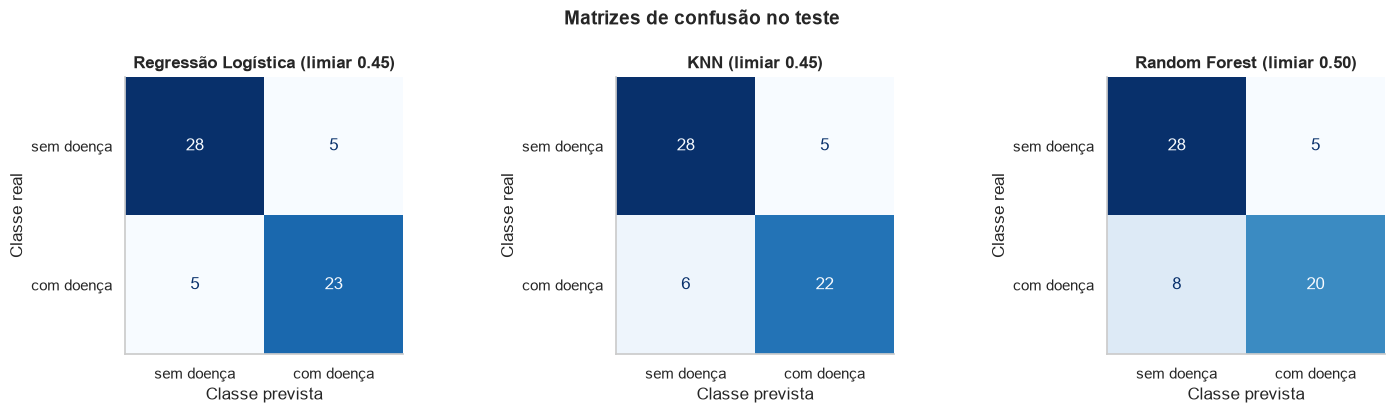

In [11]:
## Matrizes de confusão no teste
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, nome in zip(axes, tabela_teste.index):
    pred = (prob_teste[nome] >= modelos_finais[nome]["limiar"]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=["sem doença", "com doença"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False)
    ax.set_title(f"{nome} (limiar {modelos_finais[nome]['limiar']:.2f})")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
fig.suptitle("Matrizes de confusão no teste", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

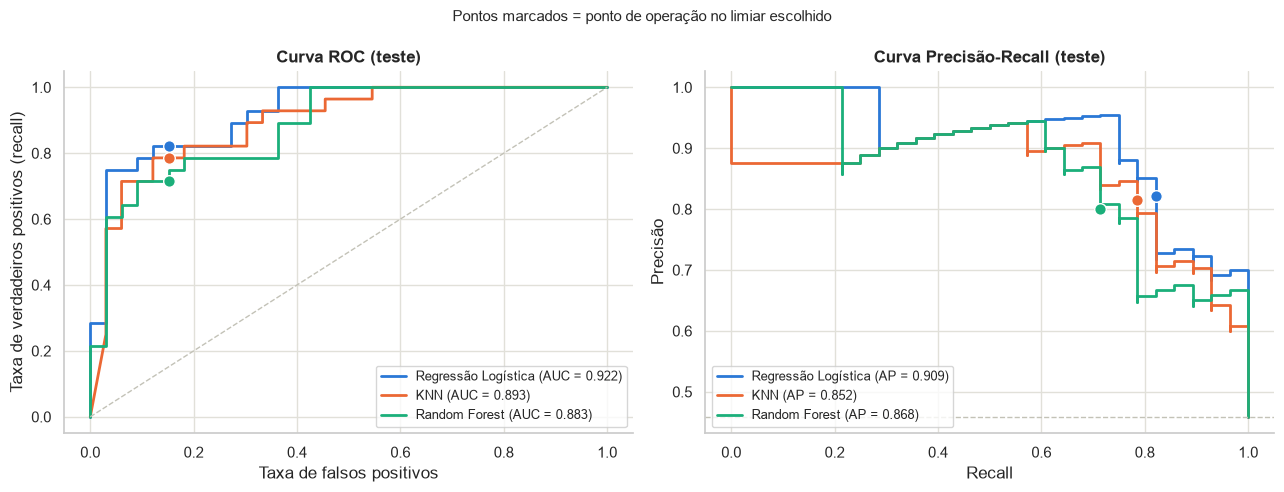

In [12]:
## Curvas ROC e Precisão-Recall no teste, com o ponto de operação (limiar escolhido) de cada modelo
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nome in tabela_teste.index:
    prob, limiar, cor = prob_teste[nome], modelos_finais[nome]["limiar"], CORES_MODELO[nome]
    pred = (prob >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()

    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=cor, linewidth=2, label=f"{nome} (AUC = {roc_auc_score(y_test, prob):.3f})")
    axes[0].scatter(fp / (fp + vn), vp / (vp + fn), color=cor, s=70, edgecolor="white", zorder=4)

    precisao, recall, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(recall, precisao, color=cor, linewidth=2, drawstyle="steps-post",
                 label=f"{nome} (AP = {average_precision_score(y_test, prob):.3f})")
    axes[1].scatter(vp / (vp + fn), vp / (vp + fp), color=cor, s=70, edgecolor="white", zorder=4)

axes[0].plot([0, 1], [0, 1], color="#c3c2b7", linestyle="--", linewidth=1)
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos (recall)")
axes[0].set_title("Curva ROC (teste)")
axes[1].axhline(y_test.mean(), color="#c3c2b7", linestyle="--", linewidth=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].set_title("Curva Precisão-Recall (teste)")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[1] else "lower right", fontsize=9)
fig.suptitle("Pontos marcados = ponto de operação no limiar escolhido", fontsize=11)
plt.tight_layout()
plt.show()

# 9. Nested CV × teste

A nested CV estima o desempenho do **procedimento** de modelagem (busca + treino); o teste avalia o **modelo final**. Os valores não precisam coincidir: com 61 pacientes no teste, um único paciente classificado de forma diferente já move o F1 em alguns pontos.

In [13]:
comparacao = pd.DataFrame({
    "F1 nested CV (média)": media_nested["F1"],
    "F1 nested CV (desvio)": desvio_nested["F1"],
    "F1 teste": tabela_teste["F1"],
})
comparacao["Diferença (nested - teste)"] = comparacao["F1 nested CV (média)"] - comparacao["F1 teste"]
display(comparacao.loc[ordem].round(3))

,F1 nested CV (média),F1 nested CV (desvio),F1 teste,Diferença (nested - teste)
Regressão Logística,0.827,0.058,0.821,0.006
KNN,0.811,0.040,0.800,0.011
Random Forest,0.808,0.039,0.755,0.053


# 10. Melhor modelo (decisão do grupo)

O grupo escolheu a **Regressão Logística** como melhor modelo, com base no desempenho no conjunto de teste. As seções seguintes analisam esse modelo:

- **Seção 11:** análise de erros agregada;
- **Seção 12:** avaliação desagregada por fatores (sexo, faixa etária e sexo × faixa etária), com intervalos de confiança de 95% por bootstrap;
- **Seção 13:** interpretabilidade (coeficientes como medidas de efeito, permutation importance, partial dependence e SHAP).

**Dados usados nas Seções 11 e 12:** as predições fora da amostra da nested CV (241 pacientes de treino, cada um previsto por um modelo que não o viu, com o limiar escolhido no seu fold) e as predições do modelo final no teste (61 pacientes, limiar 0,45). As duas fontes são reportadas separadamente.

In [14]:
MELHOR_MODELO = "Regressão Logística"
modelo_final = modelos_finais[MELHOR_MODELO]
pipe_lr, limiar_lr = modelo_final["pipeline"], modelo_final["limiar"]

## Predições fora da amostra (nested CV) e do modelo final (teste), com os atributos originais
avaliacao = pd.concat([
    X_train.assign(real=y_train, prob=predicoes_nested[MELHOR_MODELO]["prob"],
                   pred=predicoes_nested[MELHOR_MODELO]["pred"], origem="Nested CV (treino)"),
    X_test.assign(real=y_test, prob=prob_teste[MELHOR_MODELO],
                  pred=(prob_teste[MELHOR_MODELO] >= limiar_lr).astype(int), origem="Teste"),
])
avaliacao["resultado"] = np.select(
    [(avaliacao.real == 1) & (avaliacao.pred == 1), (avaliacao.real == 0) & (avaliacao.pred == 0),
     (avaliacao.real == 0) & (avaliacao.pred == 1), (avaliacao.real == 1) & (avaliacao.pred == 0)],
    ["VP", "VN", "FP", "FN"], default="")
ORIGENS = ["Nested CV (treino)", "Teste"]
print(avaliacao.groupby("origem")["resultado"].value_counts().unstack()[["VP", "VN", "FP", "FN"]])

resultado           VP   VN  FP  FN
origem                             
Nested CV (treino)  91  112  19  19
Teste               23   28   5   5


# 11. Análise de erros (agregada)

## 11.1. Qual classe é mais difícil?

Taxa de falsos negativos (doentes classificados como sem doença) e taxa de falsos positivos (pacientes sem doença classificados como doentes).

In [15]:
def taxas_de_erro(dados):
    vp, vn = (dados.resultado == "VP").sum(), (dados.resultado == "VN").sum()
    fp, fn = (dados.resultado == "FP").sum(), (dados.resultado == "FN").sum()
    return pd.Series({"Pacientes": len(dados), "Com doença": vp + fn, "Sem doença": vn + fp,
                      "Falsos negativos": fn, "Falsos positivos": fp,
                      "Taxa de falsos negativos": fn / (fn + vp), "Taxa de falsos positivos": fp / (fp + vn)})


display(avaliacao.groupby("origem").apply(taxas_de_erro).round(3))

,Pacientes,Com doença,Sem doença,Falsos negativos,Falsos positivos,Taxa de falsos negativos,Taxa de falsos positivos
origem,,,,,,,
Nested CV (treino),241.0,110.0,131.0,19.0,19.0,0.173,0.145
Teste,61.0,28.0,33.0,5.0,5.0,0.179,0.152


## 11.2. Confiança das predições

Distribuição da probabilidade prevista de doença, separada pela classe real. Pacientes do lado "errado" do limiar são os erros; os que estão longe do limiar são erros cometidos com alta confiança (amostras "confusas", cujos atributos se parecem com os da outra classe).

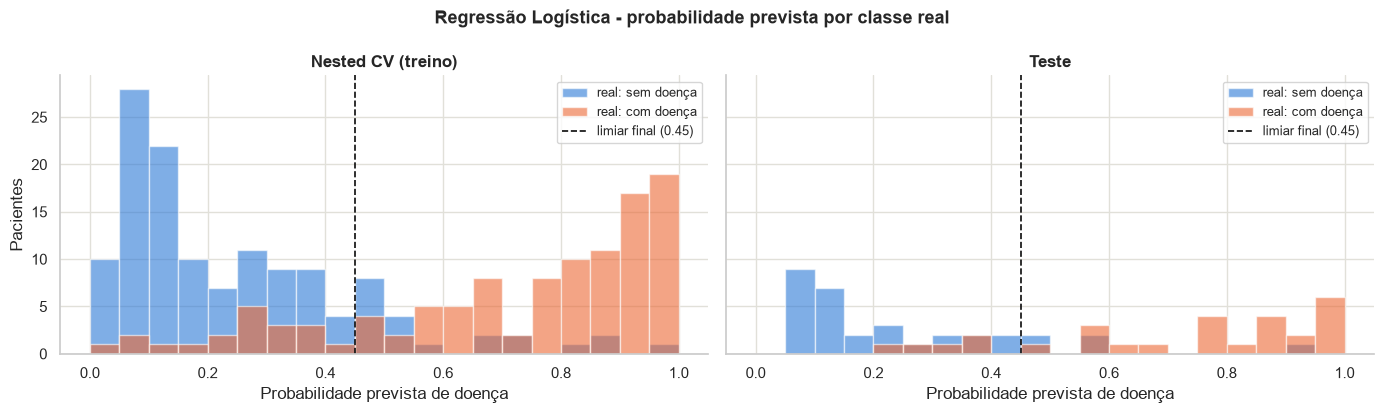

Erros com alta confiança por origem:
origem              resultado
Nested CV (treino)  FN           7
                    FP           4
Teste               FN           1
                    FP           1


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, origem in zip(axes, ORIGENS):
    dados = avaliacao[avaliacao.origem == origem]
    for classe, cor in [(0, "#2a78d6"), (1, "#eb6834")]:
        ax.hist(dados.loc[dados.real == classe, "prob"], bins=np.linspace(0, 1, 21), alpha=0.6, color=cor,
                edgecolor="white", label=f"real: {NOMES_DOENCA[classe]}")
    ax.axvline(limiar_lr, color="#0b0b0b", linestyle="--", linewidth=1.2, label=f"limiar final ({limiar_lr:.2f})")
    ax.set_title(origem)
    ax.set_xlabel("Probabilidade prevista de doença")
    ax.legend(fontsize=9)
axes[0].set_ylabel("Pacientes")
fig.suptitle("Regressão Logística - probabilidade prevista por classe real", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## Erros com alta confiança: falsos negativos com probabilidade < 0,25 e falsos positivos com probabilidade > 0,75
alta_confianca = ((avaliacao.resultado == "FN") & (avaliacao.prob < 0.25)) | \
                 ((avaliacao.resultado == "FP") & (avaliacao.prob > 0.75))
print("Erros com alta confiança por origem:")
print(avaliacao[alta_confianca].groupby(["origem", "resultado"]).size().to_string())

## 11.3. Perfil dos acertos e dos erros

Média dos atributos numéricos e proporção de alguns atributos categóricos em cada tipo de resultado (VP, VN, FP, FN), juntando as predições fora da amostra da nested CV e do teste (302 pacientes).

In [17]:
perfil = avaliacao.assign(
    **{"homens (%)": avaliacao.sex.eq(1) * 100,
       "dor assintomática, cp = 0 (%)": avaliacao.cp.eq(0) * 100,
       "angina no exercício, exang = 1 (%)": avaliacao.exang.eq(1) * 100,
       "ca ≥ 1 vaso (%)": avaliacao.ca.ge(1) * 100,
       "thal normal, thal = 2 (%)": avaliacao.thal.eq(2) * 100})
colunas_perfil = ["age", "trestbps", "chol", "thalach", "oldpeak", "homens (%)", "dor assintomática, cp = 0 (%)",
                  "angina no exercício, exang = 1 (%)", "ca ≥ 1 vaso (%)", "thal normal, thal = 2 (%)"]
tabela_perfil = perfil.groupby("resultado")[colunas_perfil].mean().loc[["VP", "FN", "VN", "FP"]].T
tabela_perfil.columns = [f"{c} (n={(avaliacao.resultado == c).sum()})" for c in tabela_perfil.columns]
display(tabela_perfil.round(1))

,VP (n=114),FN (n=24),VN (n=140),FP (n=24)
age,57.0,54.9,51.8,57.2
trestbps,134.9,132.0,128.5,133.7
chol,251.9,247.2,241.0,252.2
thalach,135.7,155.4,160.0,148.8
oldpeak,1.8,0.7,0.5,1.1
homens (%),84.2,75.0,50.7,87.5
"dor assintomática, cp = 0 (%)",83.3,37.5,20.0,45.8
"angina no exercício, exang = 1 (%)",62.3,20.8,10.0,37.5
ca ≥ 1 vaso (%),74.6,29.2,15.7,37.5
"thal normal, thal = 2 (%)",16.7,70.8,86.4,33.3


# 12. Avaliação desagregada por fatores

Fatores escolhidos pelo grupo: **sexo**, **faixa etária** (abaixo de 55 anos ou a partir de 55, a mediana de idade do treino) e a **interseção sexo × faixa etária**. Para cada grupo: número de pacientes, número de doentes, F1, taxa de falsos negativos (TFN) e taxa de falsos positivos (TFP), com intervalo de confiança de 95% por bootstrap (1000 reamostragens dentro do grupo). Métricas indefinidas (por exemplo, TFN em um grupo sem doentes) aparecem como vazias.

In [18]:
IDADE_CORTE = int(X_train["age"].median())
N_BOOTSTRAP = 1000

avaliacao["Sexo"] = avaliacao.sex.map({0: "Feminino", 1: "Masculino"})
avaliacao["Faixa etária"] = np.where(avaliacao.age < IDADE_CORTE, f"< {IDADE_CORTE}", f"≥ {IDADE_CORTE}")
avaliacao["Sexo × faixa etária"] = avaliacao["Sexo"] + ", " + avaliacao["Faixa etária"]


def f1_definido(real, pred):
    """F1 da classe positiva; indefinido (NaN) se o grupo não tem nenhum doente."""
    vp, fp, fn = ((real == 1) & (pred == 1)).sum(), ((real == 0) & (pred == 1)).sum(), ((real == 1) & (pred == 0)).sum()
    return 2 * vp / (2 * vp + fp + fn) if real.sum() > 0 else np.nan


def tfn(real, pred):
    return ((real == 1) & (pred == 0)).sum() / real.sum() if real.sum() > 0 else np.nan


def tfp(real, pred):
    return ((real == 0) & (pred == 1)).sum() / (real == 0).sum() if (real == 0).sum() > 0 else np.nan


METRICAS_GRUPO = {"F1": f1_definido, "TFN": tfn, "TFP": tfp}


def com_ic(real, pred, funcao, semente=RANDOM_STATE):
    """Valor da métrica e IC 95% por bootstrap (percentis 2,5 e 97,5)."""
    real, pred = np.asarray(real), np.asarray(pred)
    rng = np.random.default_rng(semente)
    reamostras = []
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(real), len(real))
        reamostras.append(funcao(real[idx], pred[idx]))
    reamostras = np.array(reamostras, dtype=float)
    reamostras = reamostras[~np.isnan(reamostras)]
    inferior, superior = np.percentile(reamostras, [2.5, 97.5]) if len(reamostras) else (np.nan, np.nan)
    return funcao(real, pred), inferior, superior


linhas = []
for origem in ORIGENS:
    dados_origem = avaliacao[avaliacao.origem == origem]
    grupos = [("Todos", "Todos", dados_origem)]
    for fator in ["Sexo", "Faixa etária", "Sexo × faixa etária"]:
        grupos += [(fator, valor, dados) for valor, dados in dados_origem.groupby(fator)]
    for fator, valor, dados in grupos:
        linha = {"Origem": origem, "Fator": fator, "Grupo": valor, "n": len(dados), "Com doença": int(dados.real.sum())}
        for nome_metrica, funcao in METRICAS_GRUPO.items():
            v, inf, sup = com_ic(dados.real, dados.pred, funcao)
            linha.update({nome_metrica: v, f"{nome_metrica} IC inf": inf, f"{nome_metrica} IC sup": sup})
        linhas.append(linha)
desagregado = pd.DataFrame(linhas)


def formatar(v, inf, sup):
    return "" if np.isnan(v) else f"{v:.2f} [{inf:.2f}; {sup:.2f}]"


for origem in ORIGENS:
    tabela = desagregado[desagregado.Origem == origem].copy()
    for m in METRICAS_GRUPO:
        tabela[f"{m} [IC 95%]"] = [formatar(*vals) for vals in tabela[[m, f"{m} IC inf", f"{m} IC sup"]].values]
    print(f"\n{origem}")
    display(tabela[["Fator", "Grupo", "n", "Com doença"] + [f"{m} [IC 95%]" for m in METRICAS_GRUPO]]
            .set_index(["Fator", "Grupo"]))


Nested CV (treino)


n  Com doença        F1 [IC 95%]  \
Fator               Grupo                                                 
Todos               Todos            241         110  0.83 [0.77; 0.88]   
Sexo                Feminino          79          20  0.79 [0.61; 0.91]   
                    Masculino        162          90  0.84 [0.77; 0.89]   
Faixa etária        < 55             114          36  0.78 [0.66; 0.87]   
                    ≥ 55             127          74  0.85 [0.79; 0.91]   
Sexo × faixa etária Feminino, < 55    33           2  0.80 [0.40; 1.00]   
                    Feminino, ≥ 55    46          18  0.79 [0.61; 0.92]   
                    Masculino, < 55   81          34  0.78 [0.65; 0.88]   
                    Masculino, ≥ 55   81          56  0.87 [0.80; 0.93]   

                                          TFN [IC 95%]       TFP [IC 95%]  
Fator               Grupo                                                  
Todos               Todos            0.17 [0.10; 0.25]  0.15 [0.09; 0.21]  
Sexo                Feminino         0.25 [0.06; 0.45]  0.05 [0.00; 0.11]  
                    Masculino        0.16 [0.09; 0.23]  0.22 [0.14; 0.32]  
Faixa etária        < 55             0.22 [0.10; 0.37]  0.10 [0.04; 0.18]  
                    ≥ 55             0.15 [0.07; 0.24]  0.21 [0.10; 0.32]  
Sexo × faixa etária Feminino, < 55   0.00 [0.00; 0.00]  0.03 [0.00; 0.10]  
                    Feminino, ≥ 55   0.28 [0.08; 0.50]  0.07 [0.00; 0.19]  
                    Masculino, < 55  0.24 [0.10; 0.39]  0.15 [0.06; 0.25]  
                    Masculino, ≥ 55  0.11 [0.03; 0.19]  0.36 [0.18; 0.57]


Teste


n  Com doença        F1 [IC 95%]  \
Fator               Grupo                                                
Todos               Todos            61          28  0.82 [0.70; 0.92]   
Sexo                Feminino         17           4  0.86 [0.00; 1.00]   
                    Masculino        44          24  0.82 [0.68; 0.92]   
Faixa etária        < 55             29           8  0.88 [0.67; 1.00]   
                    ≥ 55             32          20  0.80 [0.63; 0.92]   
Sexo × faixa etária Feminino, < 55    7           0                      
                    Feminino, ≥ 55   10           4  0.86 [0.00; 1.00]   
                    Masculino, < 55  22           8  0.88 [0.62; 1.00]   
                    Masculino, ≥ 55  22          16  0.79 [0.61; 0.92]   

                                          TFN [IC 95%]       TFP [IC 95%]  
Fator               Grupo                                                  
Todos               Todos            0.18 [0.04; 0.32]  0.15 [0.03; 0.28]  
Sexo                Feminino         0.25 [0.00; 1.00]  0.00 [0.00; 0.00]  
                    Masculino        0.17 [0.04; 0.32]  0.25 [0.07; 0.47]  
Faixa etária        < 55             0.12 [0.00; 0.40]  0.05 [0.00; 0.17]  
                    ≥ 55             0.20 [0.05; 0.40]  0.33 [0.08; 0.62]  
Sexo × faixa etária Feminino, < 55                      0.00 [0.00; 0.00]  
                    Feminino, ≥ 55   0.25 [0.00; 1.00]  0.00 [0.00; 0.00]  
                    Masculino, < 55  0.12 [0.00; 0.40]  0.07 [0.00; 0.25]  
                    Masculino, ≥ 55  0.19 [0.00; 0.40]  0.67 [0.22; 1.00]

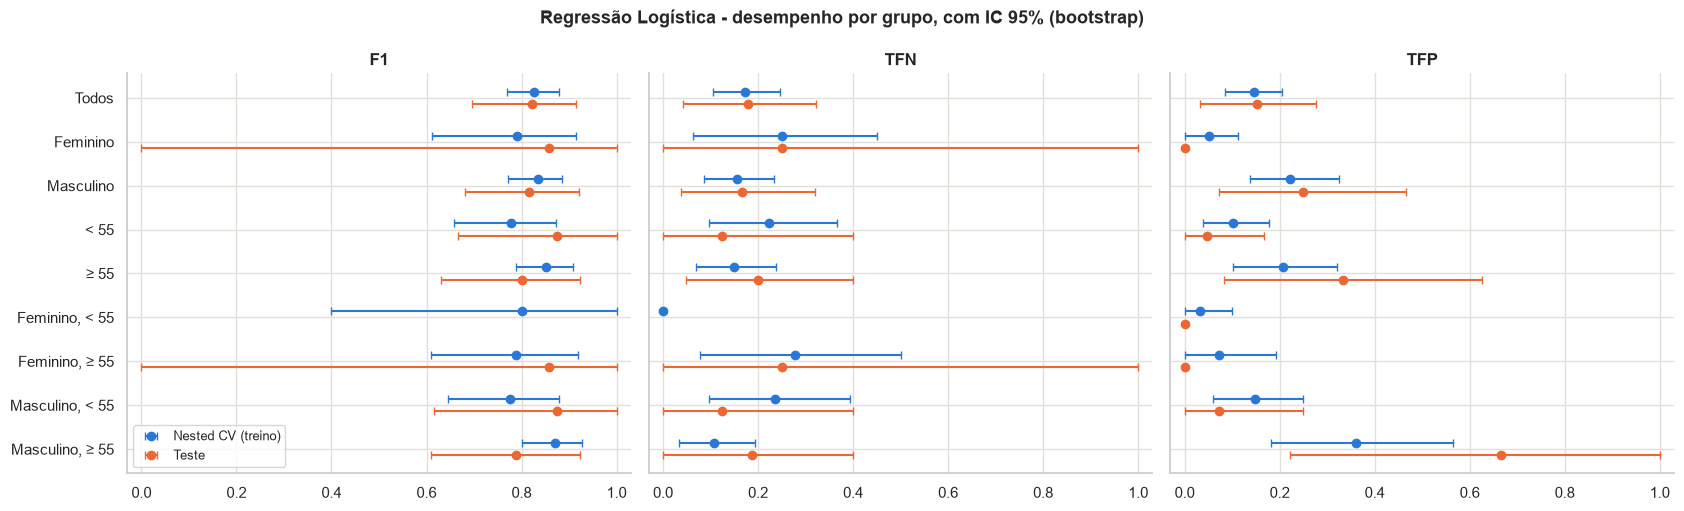

In [19]:
## F1, TFN e TFP por grupo, com IC 95% (nested CV e teste)
ordem_grupos = list(dict.fromkeys(desagregado.Grupo))
CORES_ORIGEM = {"Nested CV (treino)": "#2a78d6", "Teste": "#eb6834"}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
for ax, metrica in zip(axes, METRICAS_GRUPO):
    for k, origem in enumerate(ORIGENS):
        dados = desagregado[desagregado.Origem == origem].set_index("Grupo").reindex(ordem_grupos)
        pos = np.arange(len(ordem_grupos)) + (k - 0.5) * 0.28
        ok = dados[metrica].notna().values
        ax.errorbar(dados[metrica][ok], pos[ok],
                    xerr=[(dados[metrica] - dados[f"{metrica} IC inf"])[ok], (dados[f"{metrica} IC sup"] - dados[metrica])[ok]],
                    fmt="o", color=CORES_ORIGEM[origem], ecolor=CORES_ORIGEM[origem], elinewidth=1.5, capsize=3,
                    markersize=6, label=origem)
    ax.set_title(metrica)
    ax.set_xlim(-0.03, 1.03)
axes[0].set_yticks(range(len(ordem_grupos)), ordem_grupos)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Regressão Logística - desempenho por grupo, com IC 95% (bootstrap)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

# 13. Interpretabilidade da Regressão Logística

## 13.1. Coeficientes como medidas de efeito

O β de cada coluna é a variação no log-odds de doença quando a coluna aumenta uma unidade. Como as colunas têm escalas diferentes, β sozinho não é comparável:

- **numéricos e `ca`** foram padronizados no pipeline, então uma unidade = **1 desvio padrão** do atributo original (informado na tabela);
- **binários e colunas one-hot** valem 0 ou 1, então uma unidade = **presença** da característica.

Por isso são reportadas duas medidas de efeito:

- **odds ratio** = exp(β): por quanto as chances de doença são multiplicadas por +1 desvio padrão (numéricos) ou pela presença da característica (binários e one-hot);
- **efeito padronizado** = β × desvio padrão da coluna no treino: variação do log-odds por 1 desvio padrão de **qualquer** coluna, o que deixa todas na mesma escala para comparar a importância.

Observação: o one-hot mantém todas as categorias, então o efeito de uma categoria deve ser lido em comparação com as demais categorias do mesmo atributo.

,Coluna,Unidade do β,β (log-odds),Odds ratio exp(β),Efeito padronizado β·DP
0,ca,+1 DP (0.9 vasos),0.664,1.942,0.664
1,oldpeak,+1 DP (1.2),0.369,1.447,0.369
2,thalach,+1 DP (21.9 bpm),-0.298,0.742,-0.298
3,thal_2.0,presença (0 → 1),-0.563,0.569,-0.280
4,cp_0.0,presença (0 → 1),0.543,1.720,0.271
5,thal_3.0,presença (0 → 1),0.548,1.730,0.268
6,sex,presença (0 → 1),0.480,1.615,0.225
7,exang,presença (0 → 1),0.445,1.560,0.211
8,slope_1.0,presença (0 → 1),0.330,1.391,0.165
9,slope_2.0,presença (0 → 1),-0.298,0.742,-0.149


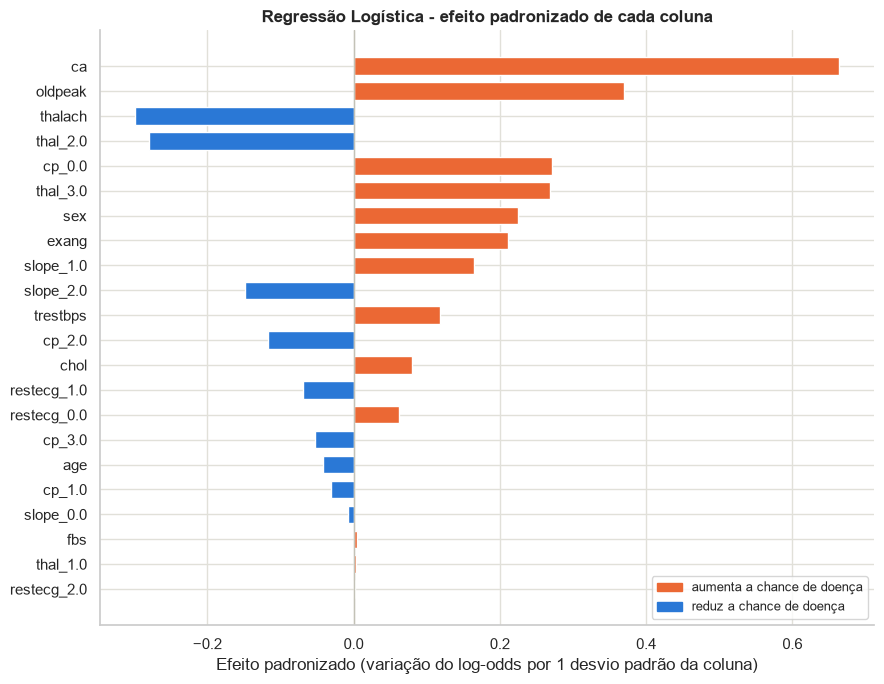

In [20]:
preprocessador_ajustado = pipe_lr.named_steps["preprocessamento"]
colunas_transformadas = [c.split("__", 1)[1] for c in preprocessador_ajustado.get_feature_names_out()]
X_train_prep = pd.DataFrame(preprocessador_ajustado.transform(X_train), columns=colunas_transformadas, index=X_train.index)
X_test_prep = pd.DataFrame(preprocessador_ajustado.transform(X_test), columns=colunas_transformadas, index=X_test.index)

coeficientes = pipe_lr.named_steps["classificador"].coef_[0]
desvio_coluna = X_train_prep.std(ddof=0).values
desvio_original = X_train[ATR_PADRONIZADOS].std(ddof=0)

UNIDADES = {"age": "anos", "trestbps": "mm Hg", "chol": "mg/dl", "thalach": "bpm", "oldpeak": "", "ca": "vasos"}
efeitos = pd.DataFrame({
    "Coluna": colunas_transformadas,
    "Unidade do β": [f"+1 DP ({desvio_original[c]:.1f} {UNIDADES[c]})".replace(" )", ")") if c in ATR_PADRONIZADOS
                     else "presença (0 → 1)" for c in colunas_transformadas],
    "β (log-odds)": coeficientes,
    "Odds ratio exp(β)": np.exp(coeficientes),
    "Efeito padronizado β·DP": coeficientes * desvio_coluna,
}).sort_values("Efeito padronizado β·DP", key=np.abs, ascending=False).reset_index(drop=True)
display(efeitos.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
cores = np.where(efeitos["Efeito padronizado β·DP"] > 0, "#eb6834", "#2a78d6")
ax.barh(efeitos["Coluna"], efeitos["Efeito padronizado β·DP"], color=cores, height=0.7)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Efeito padronizado (variação do log-odds por 1 desvio padrão da coluna)")
ax.set_title("Regressão Logística - efeito padronizado de cada coluna")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#eb6834", label="aumenta a chance de doença"),
                   Patch(color="#2a78d6", label="reduz a chance de doença")], loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## 13.2. Permutation importance (teste)

Queda do F1 no teste (com o limiar final de 0,45) quando os valores de um atributo original são embaralhados, destruindo sua relação com o alvo. A permutação é feita sobre os 13 atributos de entrada do pipeline, então os atributos codificados por one-hot são avaliados como um todo. Média e desvio padrão de 30 repetições.

,Queda média do F1,Desvio padrão
ca,0.097,0.045
cp,0.033,0.030
trestbps,0.022,0.011
thalach,0.017,0.021
restecg,0.013,0.018
chol,0.009,0.013
thal,0.009,0.034
exang,0.006,0.011
slope,0.004,0.022
oldpeak,0.002,0.018


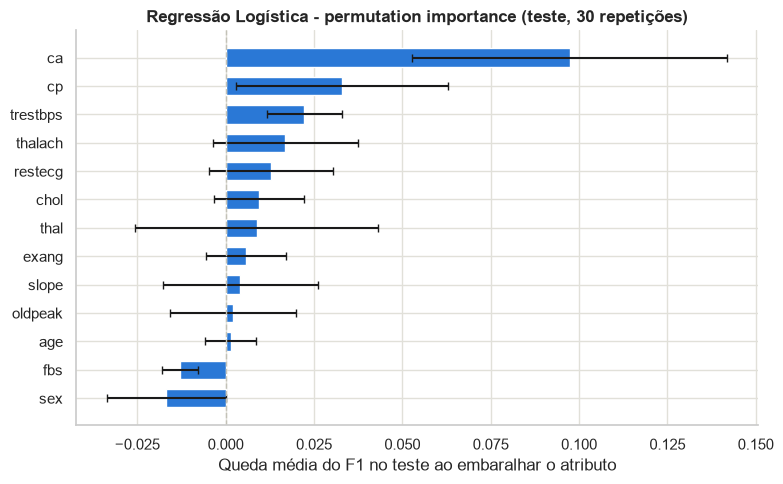

In [21]:
from sklearn.inspection import PartialDependenceDisplay, permutation_importance


def f1_com_limiar(estimador, X, y):
    return f1_score(y, (estimador.predict_proba(X)[:, 1] >= limiar_lr).astype(int))


importancia = permutation_importance(pipe_lr, X_test, y_test, scoring=f1_com_limiar, n_repeats=30,
                                     random_state=RANDOM_STATE)
tabela_importancia = pd.DataFrame({"Queda média do F1": importancia.importances_mean,
                                   "Desvio padrão": importancia.importances_std},
                                  index=X_test.columns).sort_values("Queda média do F1", ascending=False)
display(tabela_importancia.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ordem_imp = tabela_importancia.index[::-1]
ax.barh(ordem_imp, tabela_importancia.loc[ordem_imp, "Queda média do F1"],
        xerr=tabela_importancia.loc[ordem_imp, "Desvio padrão"], color="#2a78d6", height=0.65, capsize=3)
ax.axvline(0, color="#c3c2b7", linestyle="--", linewidth=1)
ax.set_xlabel("Queda média do F1 no teste ao embaralhar o atributo")
ax.set_title("Regressão Logística - permutation importance (teste, 30 repetições)")
plt.tight_layout()
plt.show()

## 13.3. Partial dependence (PDP)

Probabilidade média prevista de doença em função de cada atributo numérico, mantendo os demais atributos como estão no treino. `ca` fica de fora por conter valores ausentes antes da imputação.

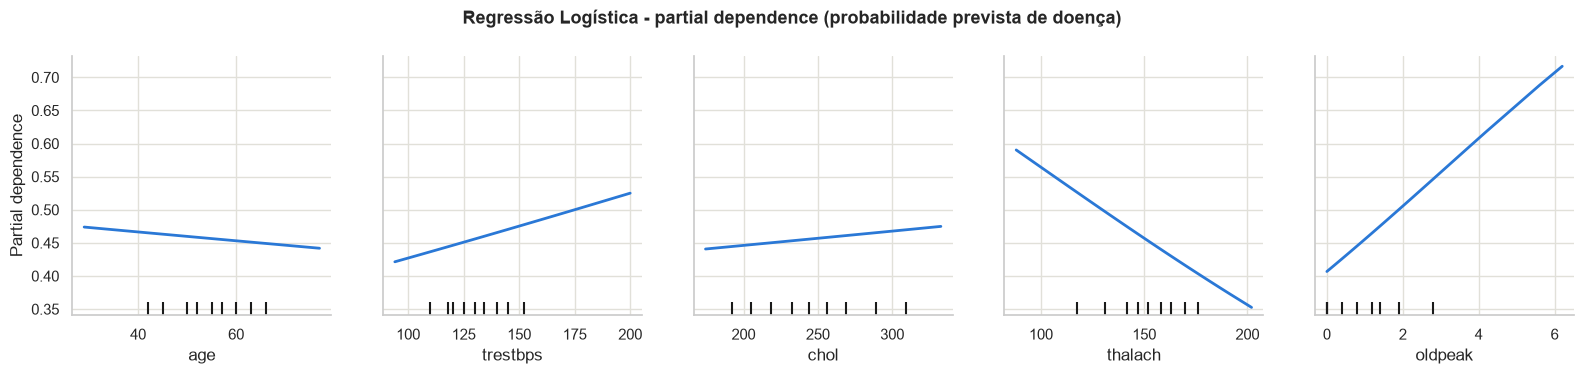

In [22]:
## O PDP do scikit-learn exige atributos em ponto flutuante (os atributos inteiros são convertidos só aqui)
fig, ax = plt.subplots(figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(pipe_lr, X_train.astype(float), ["age", "trestbps", "chol", "thalach", "oldpeak"],
                                        response_method="predict_proba", kind="average", n_cols=5, ax=ax,
                                        line_kw={"color": "#2a78d6", "linewidth": 2})
fig.suptitle("Regressão Logística - partial dependence (probabilidade prevista de doença)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## 13.4. SHAP

Contribuição de cada coluna para a predição de cada paciente do teste, em log-odds, em relação à predição média (`LinearExplainer`, usando o treino como referência). O beeswarm mostra a direção do efeito (cor = valor da coluna); o gráfico de barras soma as contribuições das colunas one-hot de cada atributo original para obter a importância global por atributo.

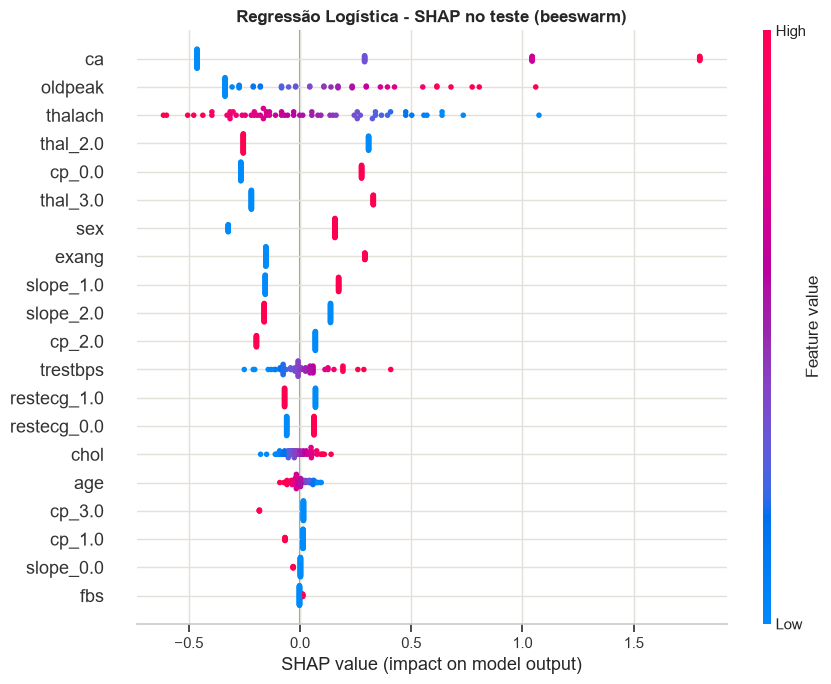

In [23]:
try:
    import shap
except ImportError:  # instala o SHAP se o ambiente não o tiver
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

## Referência: todos os 241 pacientes de treino (sem a subamostragem padrão de 100)
referencia = shap.maskers.Independent(X_train_prep, max_samples=len(X_train_prep))
explicador = shap.LinearExplainer(pipe_lr.named_steps["classificador"], referencia)
valores_shap = explicador.shap_values(X_test_prep)

shap.summary_plot(valores_shap, X_test_prep, feature_names=colunas_transformadas, show=False, plot_size=(9, 7))
plt.title("Regressão Logística - SHAP no teste (beeswarm)")
plt.tight_layout()
plt.show()

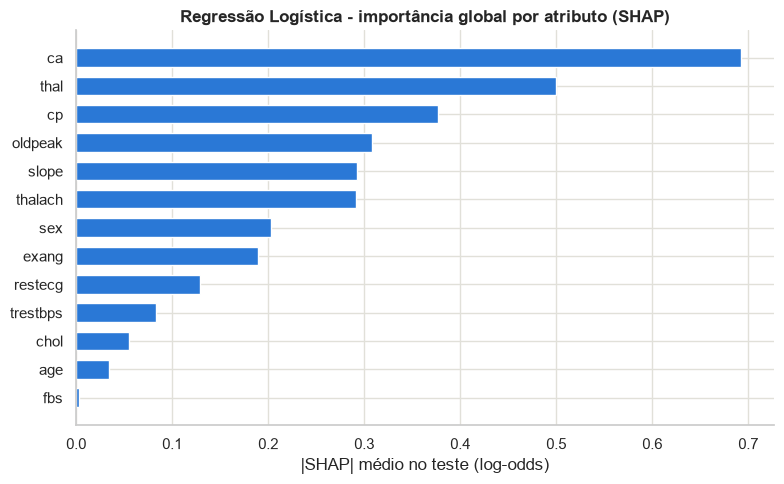

In [24]:
## Importância global por atributo original: soma das contribuições das colunas do mesmo atributo
atributo_original = [next(a for a in X_train.columns if c == a or c.startswith(a + "_")) for c in colunas_transformadas]
shap_por_atributo = pd.DataFrame(valores_shap, columns=colunas_transformadas).T.groupby(atributo_original).sum().T
importancia_shap = shap_por_atributo.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancia_shap.index, importancia_shap.values, color="#2a78d6", height=0.65)
ax.set_xlabel("|SHAP| médio no teste (log-odds)")
ax.set_title("Regressão Logística - importância global por atributo (SHAP)")
plt.tight_layout()
plt.show()

*(A interpretação dos resultados das Seções 11 a 13 fica a cargo do grupo.)*